# 2 · Light-plane calibration

With the light sheet projected on the master at known `z`, each pixel of the sheet centroid is brought into object space by intersecting its ray with the plane `z = constant` (camera model from notebook 1). The points of all the views lie on the plane of the sheet, which is estimated by least squares: `z = A·x + B·y + C`.

In [1]:
from pathlib import Path

import cv2 as cv
import matplotlib.pyplot as plt
import numpy as np

ROOT = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd()
DATA, FIGURES = ROOT / "data", ROOT / "docs" / "figures"
FIGURES.mkdir(parents=True, exist_ok=True)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})

from lightsheet3d.laser import laser_centroids
from lightsheet3d.lightplane import fit_plane, plane_errors
from lightsheet3d.pipeline import calibrate_camera, calibrate_light_plane

## Sheet extraction

The core of the sheet is saturated on all channels, while the light paper has high red but lower green and blue: the rule `min(B, G, R) ≥ 235` is used, small components (reflections) are discarded and the centroid of each row is computed. Rows without the sheet produce no points (no interpolation).

1390 rows with the sheet out of 1420


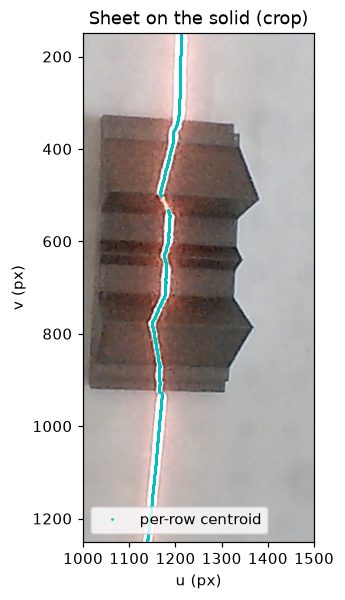

In [2]:
img = cv.imread(str(DATA / "scans" / "30o34.jpg"))
uv = laser_centroids(img)
print(f"{len(uv)} rows with the sheet out of {img.shape[0]}")

x0, x1, y0, y1 = 1000, 1500, 150, 1250
fig, ax = plt.subplots(figsize=(5, 6))
ax.imshow(cv.cvtColor(img, cv.COLOR_BGR2RGB)[y0:y1, x0:x1], extent=(x0, x1, y1, y0))
ax.plot(*uv.T, "c.", ms=1.5, label="per-row centroid")
ax.set(xlim=(x0, x1), ylim=(y1, y0), xlabel="u (px)", ylabel="v (px)", title="Sheet on the solid (crop)")
ax.grid(False); ax.legend(loc="lower left")
fig.savefig(FIGURES / "laser_centroids.png", bbox_inches="tight")

## Plane and validation

In [3]:
camera = calibrate_camera(DATA / "camera_calibration")
lp = calibrate_light_plane(DATA / "light_plane_calibration", camera.model)
A, B, C = lp.plane
cal, val = lp.points[~lp.is_validation], lp.points[lp.is_validation]
rms = lambda p: np.sqrt((plane_errors(lp.plane, p) ** 2).mean())
print(f"plane: z = {A:.3f}·x + {B:.4f}·y + {C:.1f}")
print(f"points: {len(cal)} for calibration, {len(val)} for validation (10%, chosen at random)")
print(f"orthogonal deviation from the plane: calibration rms {rms(cal):.3f} mm | validation rms {rms(val):.3f} mm | validation max {np.abs(plane_errors(lp.plane, val)).max():.2f} mm")

print("\nstricter validation: a whole view (z) is excluded and the plane is recomputed on the others")
for z in np.unique(lp.points[:, 2]):
    m = lp.points[:, 2] == z
    e = plane_errors(fit_plane(lp.points[~m]), lp.points[m])
    print(f"  leaving out z = {z:.0f} mm: rms {np.sqrt((e**2).mean()):.2f} mm")

plane: z = 3.657·x + 0.0114·y + 181.5
points: 7668 for calibration, 852 for validation (10%, chosen at random)
orthogonal deviation from the plane: calibration rms 0.524 mm | validation rms 0.510 mm | validation max 1.37 mm

stricter validation: a whole view (z) is excluded and the plane is recomputed on the others
  leaving out z = 300 mm: rms 0.97 mm
  leaving out z = 310 mm: rms 0.11 mm
  leaving out z = 320 mm: rms 0.28 mm
  leaving out z = 330 mm: rms 1.16 mm
  leaving out z = 340 mm: rms 0.91 mm
  leaving out z = 350 mm: rms 0.12 mm


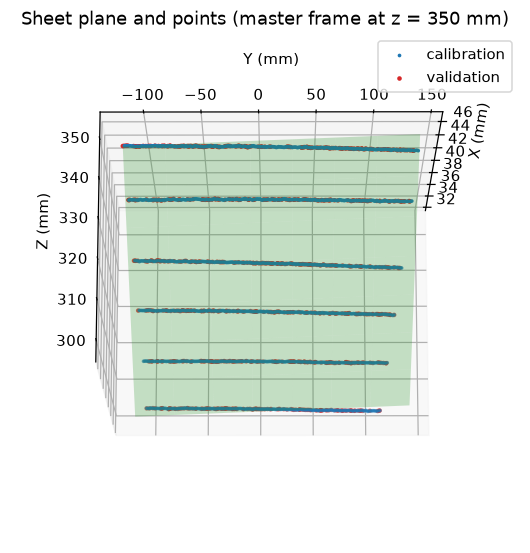

In [4]:
fig = plt.figure(figsize=(8, 6))
ax = fig.add_subplot(projection="3d")
sub = slice(None, None, 6)
ax.scatter(*cal[sub].T, s=2, c="tab:blue", label="calibration")
ax.scatter(*val.T, s=4, c="tab:red", label="validation")
gx, gy = np.meshgrid(np.linspace(*np.percentile(lp.points[:, 0], [0, 100]), 8), np.linspace(*np.percentile(lp.points[:, 1], [0, 100]), 8))
ax.plot_surface(gx, gy, A * gx + B * gy + C, alpha=0.25, color="tab:green")
ax.set(xlabel="X (mm)", ylabel="Y (mm)", zlabel="Z (mm)", title="Sheet plane and points (master frame at z = 350 mm)")
ax.legend()
ax.view_init(elev=np.degrees(np.arcsin(-1 / np.sqrt(A**2 + B**2 + 1))), azim=np.degrees(np.arctan2(B, A)))  # facing the plane
fig.savefig(FIGURES / "light_plane.png", bbox_inches="tight")

**Reading.** The deviation on the held-out points (~0.5 mm) matches the calibration one. Excluding a whole view, the error ranges from ~0.1 to ~1.1 mm: this is the order of magnitude of the uncertainty on the height. Using also the views with `z > 350 mm` (beyond the main master) the error grows (rms ~0.95 mm) and the support base turns out shifted by ~10 mm, which is why they are excluded.